# AIMMD-TIS on a 2-D toy potential: a guided tour

This notebook runs one full cycle of **AIMMD-TIS** on the Wolfe–Quapp toy potential and explains each step.
At the end you have:
- a committor model learned by AIMMD;
- a TIS calculation that uses this model as its order parameter;
- the reweighted path ensemble (RPE);
- an improved committor model trained on the RPE.

**The idea in one paragraph.** For a rare transition A → B, the ideal reaction coordinate is the *committor*
$p_B(x)$: the probability that a trajectory started at configuration $x$, with random velocities, reaches B before A.
AIMMD learns it with a neural network as the log-odds
$$q(x) = \ln\frac{p_B(x)}{1-p_B(x)}, \qquad p_B = \frac{1}{1+e^{-q}},$$
so $q \to -\infty$ in A, $q \to +\infty$ in B, and $q = 0$ is the transition-state ensemble.
TIS (transition interface sampling) then uses $q$ as its order parameter: it places interfaces on iso-$q$ surfaces and
samples paths in each interface ensemble. With multistate MBAR, these paths are combined into one *reweighted path ensemble*,
i.e. an unbiased, equilibrium-weighted set of configurations with known shooting outcomes.
That set is the training set for the next, better $q$.

### Pipeline
| Step | What | Package |
|---|---|---|
| 1 | Define the toy system (potential, states A/B, Langevin engine) | `ops_setup` |
| 2 | **AIMMD-TPS**: transition path sampling while learning $q(x)$ on the fly | `aimmd`, `aimmdTIS` |
| 3 | **Stable-state MD** in A and B (unbiased) | `openpathsampling`, `ops_setup` |
| 4 | **Interfaces** placed on $q$, starting at the edge of each stable state | `aimmdTIS` |
| 5 | **AIMMD-TIS** forward (A→B) and backward (B→A); descriptors, shot results and path extrema are stored *while sampling* | `aimmdTIS`, `ops_setup.descriptor_storage` |
| 6 | **RPE**: multistate-MBAR weights per path, crossing probabilities, forward + backward + stable data combined | `rpe_mbar` |
| 7 | **Retrain** $q$ on the RPE and place the interfaces of the next iteration | `aimmdTIS` |

Steps 5–7 form one iteration. `examples/wolfe_quapp_iterative/run_iterative.py` repeats them automatically.

### How to run
- Use the `aimmd-tis` conda environment from the README and start Jupyter **from the `examples/` folder** (the notebook reads `config_aimmd.json` from there).
- `QUICK = True` (default): small sample sizes, about 10 min on a laptop CPU and about 1.5 GB of disk (mostly the OPS `.nc` files).
  Every step runs, but the results are noisy: use it to learn the workflow, not to judge the method.
- `QUICK = False`: realistic sample sizes (4× longer TIS chains, 10× longer stable MD, full training); expect roughly 30–60 min on CPU.
- Every stage writes its results to disk and is skipped on a rerun if its results exist. Set `RERUN = True` to redo everything.

## 0. Settings

In [1]:
import json
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import openpathsampling as paths

import aimmd
import aimmdTIS
import rpe_mbar
from aimmdTIS import aimmd_setup, ToyVisualizer
from ops_setup.systems.examples.toy_systems import ToyTPSSetup
from ops_setup.descriptor_storage import build_stable_state_storage, load_stable_state_payload
from rpe_mbar.diag.crossing import bootstrap_crossing_probs

print("Imports successful!")

Imports successful!


In [2]:
QUICK = True    # small run (minutes); False = sizes of the reference run
RERUN = False   # True = redo every stage even if its results exist on disk

if QUICK:
    sizes = dict(tps_steps=100, stable_steps=5_000, tis_steps=80, thermalization=10, train_epochs=40)
    results_dir = Path("toy_tutorial_quick")
else:
    sizes = dict(tps_steps=100, stable_steps=50_000, tis_steps=300, thermalization=30, train_epochs=None)  # None: use config
    results_dir = Path("toy_tutorial_results")
print(sizes)

# Result files of every stage
tps_dir, stable_dir, tis_dir, train_dir = (results_dir / d for d in ("tps", "stable", "tis_it1", "training_it1"))
for d in (tps_dir, stable_dir, tis_dir, train_dir):
    d.mkdir(parents=True, exist_ok=True)
tps_ops_file = tps_dir / "tps.nc"                     # OPS storage of the TPS run
tps_model_file = tps_dir / "aimmd_tps.h5"             # AIMMD storage with the learned model q_0
stable_ops_files = [stable_dir / "stateA.nc", stable_dir / "stateB.nc"]
stable_descriptor_file = stable_dir / "stable_descriptor_storage"
interfaces_file = tis_dir / "interfaces.json"
retrained_model_file = train_dir / "aimmd_tis_it1.h5"

ORIGIN = "cv_q"     # name of the interface set (= order parameter q_0) in all TIS / RPE files

{'tps_steps': 100, 'stable_steps': 5000, 'tis_steps': 80, 'thermalization': 10, 'train_epochs': 40}


| Stage | Output (in `results_dir`) | QUICK | full |
|---|---|---|---|
| 2 AIMMD-TPS | `tps/tps.nc`, `tps/aimmd_tps.h5` | 100 steps | 100 steps |
| 3 Stable MD | `stable/state{A,B}.nc`, `stable/stable_descriptor_storage.*` | 2 × 5 000 steps | 2 × 50 000 steps |
| 5 AIMMD-TIS | `tis_it1/{forward,backward}/`: `.nc`, `descriptors.*`, `cv_extrema_*.csv`, `run_summary.json` | 80 steps / interface | 300 steps / interface |
| 6 RPE | `tis_it1/rpe_dataset_{forward,backward}.*` | | |
| 7 Retrain | `training_it1/aimmd_tis_it1.h5` | 40 epochs | config (early stopping) |

## 1. The toy system

The **Wolfe–Quapp potential** is a 2-D potential with two minima (states A and B) that are connected through a curved
channel. Because the transition is curved, neither $x$ nor $y$ alone is a good reaction coordinate, which makes it a
standard test for learned reaction coordinates. `scale=2` sets the barrier height. The dynamics is Langevin (BAOAB
integrator) with $k_BT = 1$, time step 0.05 and friction 10.

A and B are circles around the two minima. `ToyTPSSetup` provides the OPS engine, the states and a template snapshot.
The descriptors for the network are simply the coordinates $(x, y)$.

Setting up Langevin BAOAB integrator for toy system...
seed used for harmonic oscilattors 123
pot dimensions without oscillators: 2
harmonic oscillators omegas:
array([0., 0.])
Setting up Langevin BAOAB integrator for toy system...
Setting up toy engine for wolfe-quapp...
Creating snapshot template for toy system...
Defining states for wolfe-quapp...


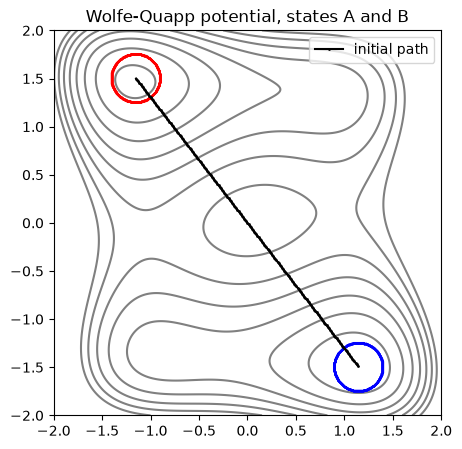

In [3]:
tps_setup = ToyTPSSetup(
    potential_name="wolfe-quapp",
    potential_kwargs={"n_harmonics": 0, "rotation_degrees": 0, "scale": 2},
    integrator_params={"dt": 0.05, "temperature": 1, "gamma": 10},
)
pes, states, engine = tps_setup.pes, tps_setup.states, tps_setup.md_engine
paths.PathMover.engine = engine
state_labels = ["A", "B"]

def descriptors_of(trajectory):
    # (n_frames, 2) array of the coordinates of an OPS trajectory
    return np.asarray([snapshot.coordinates[0] for snapshot in trajectory])

descriptor_transform = paths.FunctionCV(
    "descriptor_transform", lambda s: s.coordinates[0], cv_wrap_numpy_array=True
).with_diskcache()

# A rough first A->B path (straight interpolation, relaxed by the engine) to start TPS from
init_traj = paths.Trajectory(pes.simple_initial_path(200, engine))

viz = ToyVisualizer(pes=pes, temperature=tps_setup.integrator_params["temperature"])
fig, ax = plt.subplots(figsize=(5, 5))
viz.plot_potential_contour(ax=ax)
viz.plot_states(ax=ax)
d = descriptors_of(init_traj)
ax.plot(d[:, 0], d[:, 1], "k.-", ms=2, label="initial path")
ax.set_title("Wolfe-Quapp potential, states A and B")
ax.legend()
plt.show()

## 2. AIMMD-TPS: learn a first committor model $q_0$

Transition path sampling with two-way shooting:
1. Pick a frame on the current A→B path (the *shooting point*).
2. Draw new velocities.
3. Integrate forward and backward in time until both halves reach a state.

If one half ends in A and the other in B, the new path is accepted.

AIMMD adds two things:
- **Shooting-point selection.** The selector prefers frames with $q \approx 0$ (a Lorentzian in $q$), i.e. frames the
  model thinks are close to the transition state. That is where shots are most informative.
- **Learning from every shot.** Each shot gives the number of trajectories that reached A and B from the shooting point.
  These counts are a binomial sample of $p_B$ at that point, so they form a training set for $q(x)$. The model is
  retrained during the run (hooks `TrainingHook`, `AimmdStorageHook`, `DensityCollectionHook`). How often depends on
  the expected-efficiency settings in `config_aimmd.json`.

The model and the training set go to an AIMMD storage (`.h5`); the paths go to an OPS storage (`.nc`).

In [4]:
config = aimmdTIS.Tools.read_config("config_aimmd.json")
# The toy network is small; CPU is fast enough and gives identical results on every machine.
config["AIMMD_settings"]["use_GPU"] = False
aimmd_set = aimmd_setup.AIMMDSetup(
    config, descriptor_dim=pes.n_dims_pot, states=states, print_config=False
)

if RERUN or not tps_model_file.exists():
    network = tps_setup.create_network()
    aimmd_storage = aimmd.Storage(str(tps_model_file), "w")
    model = aimmd_set.setup_RCModel(aimmd_storage)
    selector = aimmd_set.setup_selector(model)
    trainset = aimmd.TrainSet(n_states=len(states))

    move_scheme = tps_setup.create_move_scheme(network, "TwoWay", selector=selector)
    initial_conditions = move_scheme.initial_conditions_from_trajectories(init_traj)
    initial_conditions.sanity_check()

    storage = paths.Storage(str(tps_ops_file), "w", template=tps_setup.template)
    for obj in (tps_setup.template, engine, move_scheme, network):
        storage.save(obj)
    sampler = paths.PathSampling(storage, move_scheme, initial_conditions)
    sampler.attach_hook(aimmd.ops.TrainingHook(model, trainset))
    sampler.attach_hook(aimmd.ops.AimmdStorageHook(aimmd_storage, model, trainset))
    sampler.attach_hook(aimmd.ops.DensityCollectionHook(model))
    sampler.run(sizes["tps_steps"])
    storage.close()
    aimmd_storage.close()
else:
    print(f"Using existing TPS results in {tps_dir}")

Working on Monte Carlo cycle number 100
Running for 31 seconds -  0.32 seconds per step
Estimated time remaining: 0 seconds


DONE! Completed 100 Monte Carlo cycles.


TPS steps stored: 101, last path has 174 frames


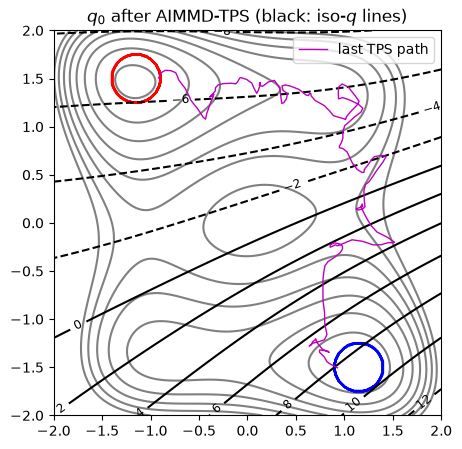

In [5]:
def load_model(path):
    # Most recent committor model from an AIMMD storage, on the CPU and in evaluation mode
    store = aimmd.Storage(str(path), "r")
    model = store.rcmodels["most_recent"]
    store.close()
    model.nnet.to("cpu")
    model.nnet.eval()
    return model

def q_of(model, descriptors):
    # q(x) = ln(p_B / p_A) of a model on an (n, 2) descriptor array
    q = model.log_prob(np.atleast_2d(descriptors), use_transform=False, batch_size=None)
    return np.asarray(q).reshape(-1)

tps_model = load_model(tps_model_file)

# The last accepted TPS path starts the TIS chains later on.
tps_storage = paths.Storage(str(tps_ops_file), "r")
initial_path_TIS = tps_storage.steps[-1].active[0].trajectory
print(f"TPS steps stored: {len(tps_storage.steps)}, last path has {len(initial_path_TIS)} frames")

fig, ax = plt.subplots(figsize=(5, 5))
viz.plot_potential_contour(ax=ax)
viz.plot_states(ax=ax)
viz.plot_q_contours(tps_model, ax=ax, levels=viz.levels_q, colors="k", linewidths=1.5)
d = descriptors_of(initial_path_TIS)
ax.plot(d[:, 0], d[:, 1], "m-", lw=1, label="last TPS path")
ax.set_title(r"$q_0$ after AIMMD-TPS (black: iso-$q$ lines)")
ax.legend()
plt.show()

**What to look for.** The iso-$q$ lines should cross the channel between A and B roughly perpendicular to it, with the
$q=0$ line near the saddle. After only ~100 TPS steps the model is rough, in particular far from the paths it has seen.
TIS and the reweighting below are designed to correct that.

## 3. Stable-state MD

Plain MD started inside A and inside B. These trajectories are used twice:
- **Interface placement (step 4):** they show which $q$ values the system takes while it is still inside a state.
  The first TIS interface $\lambda_0$ is placed at the edge of that range.
- **RPE (step 6):** TIS paths only cover the region beyond $\lambda_0$. The part of the equilibrium distribution
  inside and around the states comes from this MD, weighted by the flux through $\lambda_0$.

The OPS trajectories are converted once into a compact `DescriptorStorage` (descriptors + in-state flags),
and only that storage is used afterwards.

5000 MD steps in stateA


5000 MD steps in stateB


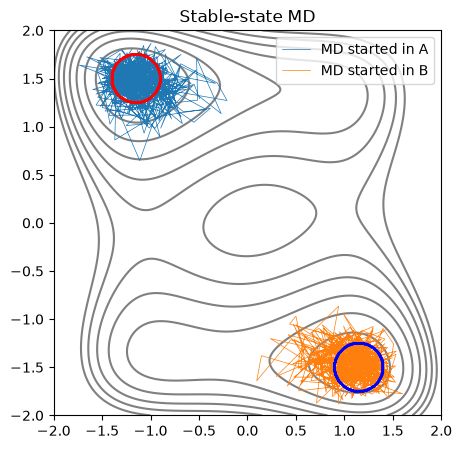

In [6]:
if RERUN or not stable_descriptor_file.with_suffix(".meta.json").exists():
    for state, storage_path in zip(states, stable_ops_files):
        start = next(snap for snap in init_traj if state(snap))   # first frame of the initial path inside the state
        storage = paths.Storage(str(storage_path), "w", template=tps_setup.template)
        storage.save(engine)
        storage.tag["template"] = start
        sim = paths.DirectSimulation(storage=storage, engine=engine, states=list(states), initial_snapshot=start)
        print(f"{sizes['stable_steps']} MD steps in {state.name}")
        sim.run(sizes["stable_steps"])
        storage.close()

    build_stable_state_storage(
        storage_paths=stable_ops_files,
        descriptor_transform=descriptor_transform,
        output_path=stable_descriptor_file,
        state_volumes=states,
        state_labels=state_labels,
        descriptor_name="descriptors",
        set_name="stable",
        method_type="stable-state",
    )

stable_payload = load_stable_state_payload(
    stable_descriptor_file, descriptor_name="descriptors", set_name="stable", state_labels=state_labels
)
data_stable = {k: stable_payload[k] for k in ("descriptors", "shot_results", "in_state_flags")}

# All stable frames in one array, plus an (n, 2) in-state mask (column 0: in A, column 1: in B)
stable_desc = np.concatenate(data_stable["descriptors"], axis=0)
stable_in_state = np.zeros((len(stable_desc), 2), dtype=bool)
offset = 0
for i, flags in enumerate(data_stable["in_state_flags"]):
    stable_in_state[offset:offset + len(flags), i] = flags
    offset += len(flags)

fig, ax = plt.subplots(figsize=(5, 5))
viz.plot_potential_contour(ax=ax)
for i, label in enumerate(state_labels):
    d = data_stable["descriptors"][i][::10]
    ax.plot(d[:, 0], d[:, 1], lw=0.5, label=f"MD started in {label}")
viz.plot_states(ax=ax)
ax.set_title("Stable-state MD")
ax.legend()
plt.show()

## 4. Interfaces on $q_0$

TIS needs a set of nested interfaces $\lambda_0 < \lambda_1 < \dots$ between A and B. Here they are iso-$q$ surfaces of
the model.
- **Forward set (A→B):** $\lambda_0$ is the largest $q$ seen inside A during stable MD.
- **Backward set (B→A):** $\lambda_0$ is the smallest $q$ seen inside B.

Each next interface is placed so that, if $q$ were the exact log-odds committor, a path that reaches interface $i$
would reach interface $i+1$ with probability `overlap` (here 0.2):
$$\frac{p_B(\lambda_i)}{p_B(\lambda_{i+1})} = \text{overlap}
\;\Rightarrow\; \lambda_{i+1} = -\ln\!\big(\text{overlap}\,(1+e^{-\lambda_i}) - 1\big).$$

Two safety rules matter for an early (miscalibrated) model:
- interfaces must lie in front of the *other* state's $q$ range, otherwise no path can cross them;
- each set ends at (or just past) $q=0$. If the overlap rule stops earlier, an interface at $q=0$ is added, so that
  forward and backward together cover the whole range and meet at the transition state.

stable_state A data falls in q-range [-7.34655762 -6.01368427]
stable_state B data falls in q-range [7.53963184 9.90510845]
Forward interfaces: -6.01 -4.39 -2.73 -0.82
Backward interfaces: 7.53 5.92 4.3 2.63 0.68
forward : [-6.01, -4.39, -2.73, -0.82, 0.0]
backward: [7.53, 5.92, 4.3, 2.63, 0.68, 0.0]


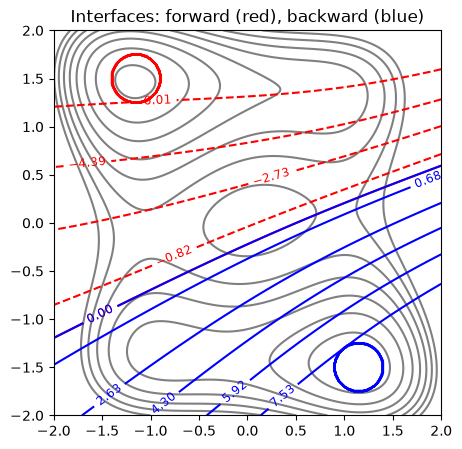

In [7]:
def place_interfaces(model, overlap=0.2, n_min=2, overshoot=1.0):
    info = aimmdTIS.check_interfaces(model, state_labels, stable_desc, in_state=stable_in_state, overlap=overlap)
    q_stable = q_of(model, stable_desc)
    q_A_max = float(q_stable[stable_in_state[:, 0]].max())
    q_B_min = float(q_stable[stable_in_state[:, 1]].min())
    if q_B_min - q_A_max < 2.0:
        raise RuntimeError(f"q does not separate the states (q_A_max={q_A_max:.2f}, q_B_min={q_B_min:.2f}); "
                           "run more TPS steps.")
    forward = [float(v) for v in (info["forward_interfaces"] if info["forward_interfaces"] is not None else []) if v < q_B_min]
    backward = [float(v) for v in (info["backward_interfaces"] if info["backward_interfaces"] is not None else []) if v > q_A_max]
    if len(forward) < n_min or len(backward) < n_min:   # overlap rule failed: evenly spaced interfaces
        grid = np.round(np.linspace(q_A_max, q_B_min, n_min + 2), 2)
        forward, backward = [float(v) for v in grid[:-1]], [float(v) for v in grid[1:][::-1]]
        print("overlap rule gave too few interfaces; using evenly spaced ones")
    forward = [v for v in forward if v <= overshoot]
    backward = [v for v in backward if v >= -overshoot]
    # both sets must reach the transition state q = 0, where they are joined
    if not forward or max(forward) < 0.0:
        forward.append(0.0)
    if not backward or min(backward) > 0.0:
        backward.append(0.0)
    # forward ascending, backward descending: the order rpe_mbar's solver expects
    return {"forward": sorted(forward), "backward": sorted(backward, reverse=True)}

if RERUN or not interfaces_file.exists():
    interfaces = place_interfaces(tps_model)
    interfaces_file.write_text(json.dumps(interfaces, indent=2))
interfaces = json.loads(interfaces_file.read_text())
print("forward :", interfaces["forward"])
print("backward:", interfaces["backward"])

fig, ax = plt.subplots(figsize=(5, 5))
viz.plot_potential_contour(ax=ax)
viz.plot_states(ax=ax)
viz.plot_q_contours(tps_model, ax=ax, levels=interfaces["forward"], colors="r", linewidths=1.5)
viz.plot_q_contours(tps_model, ax=ax, levels=sorted(interfaces["backward"]), colors="b", linewidths=1.5)
ax.set_title("Interfaces: forward (red), backward (blue)")
plt.show()

## 5. AIMMD-TIS

For every interface $\lambda_i$ we sample the TIS path ensemble: paths that start in the origin state (A for forward,
B for backward), cross $\lambda_i$ and end in A or B. The order parameter is $q_0$, the model is **frozen** during TIS.
Paths that start in the state count as crossing only after they have left it.

Settings:
- **Two-way shooting** with new random velocities at the shooting point.
- **Gaussian selector:** shooting points are drawn with weight $\exp\!\big(-(q-\lambda_i \mp 0.2)^2/2\big)$, i.e. near the
  interface. Shots from there are most likely to give a new, accepted path.
- All interfaces of one direction start from the last TPS path, which is a valid path for every interface.

**What is stored while sampling** (`extrema_source="on_the_fly"` and `descriptor_storage_path`). After every MC step,
including step 0 (the initial path):
- the path's descriptors and shot result go to a `DescriptorStorage` (`descriptors.*`);
- the path's minimum and maximum $q$ outside the origin state go to `cv_extrema_*.csv`.

Row *k* of the CSV, entry *k* of the descriptor storage and MC step *k* are the same path. Steps 6 and 7 use only these
files, so the OPS `.nc` storages are **never opened again** after sampling, and nothing is recomputed from them.

In [8]:
def run_tis(direction):
    out = tis_dir / direction
    summary_file = out / "run_summary.json"
    if not RERUN and summary_file.exists():
        print(f"Using existing {direction} TIS results in {out}")
        return json.loads(summary_file.read_text())
    if out.exists():
        shutil.rmtree(out)   # a DescriptorStorage would otherwise be appended to
    tis = aimmdTIS.AIMMD_TIS(
        engine=engine, AIMMD_model=tps_model, stateA=states[0], stateB=states[1],
        directory=out, cvq_type="pkl", cv_label=ORIGIN,
    )
    rows = tis.run_TIS_sequentially(
        n_mc_steps=sizes["tis_steps"],
        initial_path=initial_path_TIS,
        interface_values=interfaces[direction],
        template=tps_setup.template,
        scheme_move="TwoWay",
        scheme_selector="Gaussian",
        scheme_modifier="RandomVelocities",
        gaussian_parameter_width=1.0,
        gaussian_parameter_shift=0.2,
        direction=direction,
        directory=out,
        overwrite=True,
        origin_label=ORIGIN,
        descriptor_storage_path=out / "descriptors",
        descriptor_set_name=ORIGIN,
        extrema_source="on_the_fly",
    )
    for row in rows:
        row["descriptor_storage"] = str(out / "descriptors")
    summary_file.write_text(json.dumps(rows, indent=2))
    return rows

tis_rows = {direction: run_tis(direction) for direction in ("forward", "backward")}
tps_storage.close()   # the TPS path is no longer needed

Working on Monte Carlo cycle number 80
Starting simulation...
Working on first step


DONE! Completed 80 Monte Carlo cycles.


  step 80/80 | step=0.2s avg=0.4s | elapsed=0d 00:00 ETA=0d 00:00


snapshots: 30298
trajectories: 81
samples: 82
storing path extrema (on_the_fly)
Finished interface 0.0. Storage: toy_tutorial_quick/tis_it1/backward/aimmd_tis_storage_backward_i0.nc


### Inspect the sampled paths

The cell below reads the paths of the first forward interface from the descriptor storage and reports:
- how many shots were accepted (a new path differs from the previous one);
- the path lengths.

As a rule of thumb, an acceptance ratio between 0.2 and 0.6 is healthy. A very low ratio means the shooting points
lie too far beyond the interface.

direction interface  paths acc. ratio  mean len  max len
  forward     -6.01     70       0.54      15.8       54
  forward     -4.39     70       0.39     236.5      665
  forward     -2.73     70       0.33     298.9      687
  forward     -0.82     70       0.23     259.5      539
  forward      0.00     70       0.29     232.2      416
 backward      7.53     70       0.42      13.6       49
 backward      5.92     70       0.44      55.1      433
 backward      4.30     70       0.36     135.8      562
 backward      2.63     70       0.39     138.9      771
 backward      0.68     70       0.40     430.6     1211
 backward      0.00     70       0.26     188.6      427


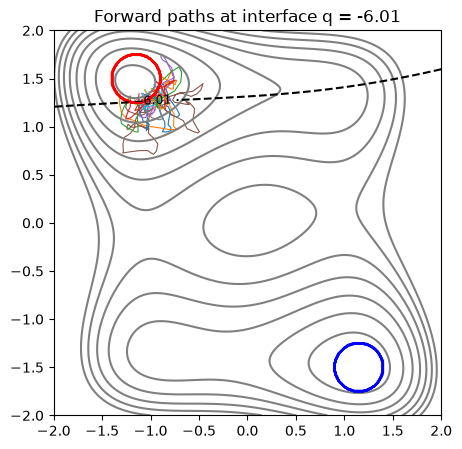

In [9]:
n_skip = sizes["thermalization"] + 1   # step 0 is the initial (TPS) path; then `thermalization` steps are discarded

def path_stats(row):
    paths_ = [d for _, d, _ in aimmdTIS.trajectories_from_descriptor_storage(
        row["descriptor_storage"], ORIGIN, row["interface_value"])]
    changed = [p.shape != q.shape or not np.array_equal(p, q) for p, q in zip(paths_[1:], paths_[:-1])]
    lengths = [len(p) for p in paths_[n_skip:]]
    return paths_, np.mean(changed), np.mean(lengths), np.max(lengths)

print(f"{'direction':>9} {'interface':>9} {'paths':>6} {'acc. ratio':>10} {'mean len':>9} {'max len':>8}")
for direction, rows in tis_rows.items():
    for row in rows:
        p, acc, mean_len, max_len = path_stats(row)
        print(f"{direction:>9} {row['interface_value']:>9.2f} {len(p) - n_skip:>6d} {acc:>10.2f} {mean_len:>9.1f} {max_len:>8d}")

row = tis_rows["forward"][0]
paths_first, *_ = path_stats(row)
fig, ax = plt.subplots(figsize=(5, 5))
for d in paths_first[n_skip::max(1, len(paths_first) // 25)]:
    ax.plot(d[:, 0], d[:, 1], lw=0.8)
viz.plot_potential_contour(ax=ax)
viz.plot_states(ax=ax)
viz.plot_q_contours(tps_model, ax=ax, levels=[row["interface_value"]], colors="k", linewidths=1.5)
ax.set_title(f"Forward paths at interface q = {row['interface_value']}")
plt.show()

## 6. Reweighted path ensemble (RPE)

Each interface ensemble samples paths with a bias: only paths that cross $\lambda_i$ are accepted. To combine all
interfaces into one unbiased path ensemble, every path gets a weight. This is the multistate-MBAR solution
(`rpe_mbar.solve_weights_multiset`). It uses only each path's maximum $q$ (forward) or minimum $q$ (backward), which
is what the extrema CSV files contain.

Steps:
1. **Extrema → MBAR weights.** Load the CSVs from MC step `n_skip` on and solve for one weight per path.
2. **Descriptors → `RpeDataset`.** `aimmdTIS.rpe_dataset_from_descriptor_storage` collects every path's frames and shot
   results from the descriptor storages, from the same step `n_skip` on. It does not open any OPS storage. Using the
   same `n_skip` in 1 and 2 keeps paths and weights aligned.
3. **Crossing probability** $P_A(q \mid \lambda_0)$: the probability that a path leaving A reaches $q$. On a log scale it
   should decrease smoothly to a plateau near $q=0$ and beyond. Jumps between interfaces mean too few paths or too
   little overlap.

In [10]:
spec = rpe_mbar.InterfaceFunctionSpec(filename=ORIGIN, cv_column_base=ORIGIN, iteration=None)
rpe = {}
for direction, rows in tis_rows.items():
    iface_values = [row["interface_value"] for row in rows]
    data, _, _ = rpe_mbar.load_extrema_as_dict_iterative(
        run_folder=tis_dir / direction,
        direction=direction,
        interface_functions=[spec],
        interfaces_by_origin={ORIGIN: iface_values},
        n_thermalization=n_skip,
        iterations=None,
        strict=True,
    )
    dataset_file = tis_dir / f"rpe_dataset_{direction}"
    if RERUN or not dataset_file.with_suffix(".meta.json").exists():
        dataset = aimmdTIS.rpe_dataset_from_descriptor_storage(rows, ORIGIN, n_skip=n_skip)
        dataset.save(dataset_file)
    dataset = rpe_mbar.RpeDataset.load(dataset_file)

    # paths in the extrema data and in the dataset must be the same, interface by interface
    for v in iface_values:
        n_extrema = len(data[ORIGIN][f"{v}"][ORIGIN])
        n_dataset = len(dataset.sets[ORIGIN].interfaces[f"{v}"].trajectories)
        assert n_extrema == n_dataset, (direction, v, n_extrema, n_dataset)

    weights, _, _ = rpe_mbar.solve_weights_multiset(data, direction=direction)
    rpe[direction] = dict(data=data, dataset=dataset, weights=weights)
    print(f"{direction}: {len(weights)} paths, weights sum = {weights.sum():.3f}")
    print(dataset.summary())

forward: 350 paths, weights sum = 1.000
RPE Dataset Summary

Set: cv_q
  Interface -6.01: 70 trajectories, 1108 points [weights: N]
  Interface -4.39: 70 trajectories, 16554 points [weights: N]
  Interface -2.73: 70 trajectories, 20920 points [weights: N]
  Interface -0.82: 70 trajectories, 18167 points [weights: N]
  Interface 0.0: 70 trajectories, 16253 points [weights: N]

Total: 350 trajectories, 73002 points
backward: 420 paths, weights sum = 1.000
RPE Dataset Summary

Set: cv_q
  Interface 7.53: 70 trajectories, 951 points [weights: N]
  Interface 5.92: 70 trajectories, 3858 points [weights: N]
  Interface 4.3: 70 trajectories, 9503 points [weights: N]
  Interface 2.63: 70 trajectories, 9726 points [weights: N]
  Interface 0.68: 70 trajectories, 30145 points [weights: N]
  Interface 0.0: 70 trajectories, 13205 points [weights: N]

Total: 420 trajectories, 67388 points


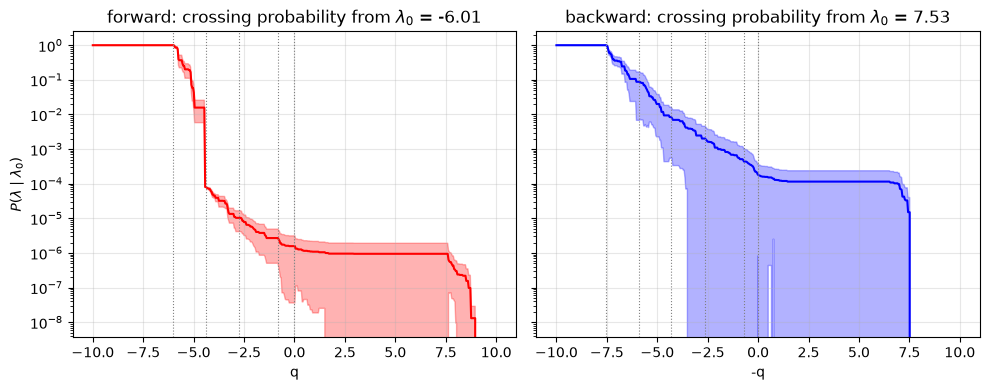

In [11]:
bins_q = np.linspace(-10, 10, 500)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, direction, sign, color in zip(axes, ("forward", "backward"), (1, -1), ("r", "b")):
    lam0 = interfaces[direction][0]
    cp = bootstrap_crossing_probs(
        data=rpe[direction]["data"], interface_0=sign * lam0, n_bootstrap=20,
        direction=direction, set_analysis=ORIGIN, bins=bins_q,
    )
    ax.plot(cp["bins"], cp["bootstrap_mean"], color=color)
    ax.fill_between(cp["bins"], cp["bootstrap_mean"] - cp["bootstrap_std"],
                    cp["bootstrap_mean"] + cp["bootstrap_std"], color=color, alpha=0.3)
    for v in interfaces[direction]:
        ax.axvline(sign * v, color="gray", ls=":", lw=0.8)
    ax.set_yscale("log")
    ax.set_xlabel("q" if direction == "forward" else "-q")
    ax.set_title(f"{direction}: crossing probability from $\\lambda_0$ = {lam0}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$P(\lambda \mid \lambda_0)$")
plt.tight_layout()
plt.show()

### Forward + backward + stable states → one training set

`rpe_mbar.build_reweighted_rpe_trainset` merges the three sources into one equilibrium-weighted set of frames with
shooting outcomes:
- **Forward paths** (from A) and **backward paths** (from B) each carry MBAR weights. Reactive paths (A↔B) appear in
  both ensembles. The factor $c_{AB}$ = (forward reactive weight) / (backward reactive weight) rescales the backward
  ensemble so that both describe the same equilibrium.
- **Stable-state frames** cover the region before $\lambda_0$. They are scaled by the number of first crossings of
  $\lambda_0$ in the stable MD (the flux), so they connect smoothly to the path ensembles.

The shot result of a frame is the pair (paths ending in A, paths ending in B) for the path it belongs to. In equilibrium,
the weighted fraction ending in B at each $x$ is an estimate of $p_B(x)$.

In [12]:
desc_f, weights_f, shot_f, counts_f = rpe_mbar.get_descriptors_and_weights(
    rpe["forward"]["data"], rpe["forward"]["weights"], rpe["forward"]["dataset"])
desc_b, weights_b, shot_b, counts_b = rpe_mbar.get_descriptors_and_weights(
    rpe["backward"]["data"], rpe["backward"]["weights"], rpe["backward"]["dataset"])

print("paths (A->A, A<->B, B->B)  forward:", counts_f, " backward:", counts_b)
if counts_f[1] == 0 or counts_b[1] == 0:
    raise RuntimeError("No reactive paths in one direction: c_AB is undefined. "
                       "Increase sizes['tis_steps'] (or set QUICK = False) and rerun with RERUN = True.")

state_function_A = lambda d: np.hypot(d[:, 0] - pes.state_A[0], d[:, 1] - pes.state_A[1])
state_function_B = lambda d: -np.hypot(d[:, 0] - pes.state_B[0], d[:, 1] - pes.state_B[1])

rpe_full = rpe_mbar.build_reweighted_rpe_trainset(
    desc_f=desc_f, w_f=weights_f, shot_f=shot_f, counts_f=counts_f,
    desc_b=desc_b, w_b=weights_b, shot_b=shot_b, counts_b=counts_b,
    weights_per_path_f=rpe["forward"]["weights"],     # MBAR weight of each path
    weights_per_path_b=rpe["backward"]["weights"],
    data_stable=data_stable,
    interface_functions=[lambda d: q_of(tps_model, d)],
    first_interfaces_forward=[interfaces["forward"][0]],
    first_interfaces_backward=[interfaces["backward"][0]],
    state_function_A=state_function_A, state_threshold_A=pes.state_boundary,
    state_function_B=state_function_B, state_threshold_B=-pes.state_boundary,
    cutoff_beyond_joined_interface=False,
    name_lambda_functions=[ORIGIN],
)
desc_total, w_total, shots_total = rpe_full["descriptors"], rpe_full["weights"], rpe_full["shot_results"]
print(f"RPE training set: {len(desc_total)} frames, c_AB = {rpe_full['c_AB']:.3f}")
print("stable frames used per state:", [int(np.sum(f)) for f in rpe_full["stable_flags"]])

paths (A->A, A<->B, B->B)  forward: (279, 71, 0)  backward: (0, 70, 350)
Effective counts for A and B: n_eff_A=69, n_eff_B=98
RPE training set: 148549 frames, c_AB = 1.014
stable frames used per state: [4286, 3873]


**Reading the three panels below.**
1. The weighted density of the RPE frames, i.e. the equilibrium distribution, on a log scale. It is high in the states and
   low along the channel. Without reweighting, the path frames would be strongly over-represented near the barrier.
2. The RPE committor estimate $p_B(x)$ per histogram bin: weighted fraction of frames whose path ended in B.
   It should go from 0 at A to 1 at B, with the 0.5 region at the transition state.
3. The same estimate as log-odds, $\ln(p_B/(1-p_B))$, which is what the network learns. Noise in sparsely sampled bins
   shows up here first.

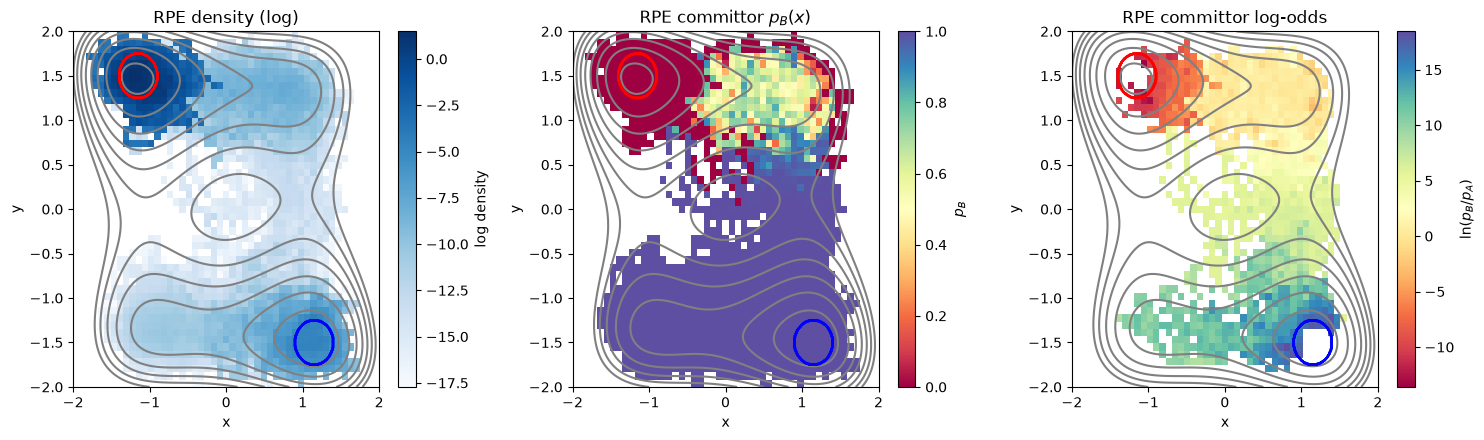

In [13]:
xedges = yedges = np.linspace(-2, 2, 50)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
h = lambda w: np.histogram2d(desc_total[:, 0], desc_total[:, 1], bins=[xedges, yedges], weights=w, density=True)[0]
hist, hist_A, hist_B = h(w_total), h(w_total * shots_total[:, 0]), h(w_total * shots_total[:, 1])
with np.errstate(divide="ignore", invalid="ignore"):
    p_b = hist_B / (hist_A + hist_B)
    panels = [
        (np.log(hist.T), "Blues", "log density", "RPE density (log)", {}),
        (p_b.T, "Spectral", r"$p_B$", r"RPE committor $p_B(x)$", dict(vmin=0, vmax=1)),
        (np.log(p_b.T) - np.log(1 - p_b.T), "Spectral", r"$\ln(p_B/p_A)$", "RPE committor log-odds", {}),
    ]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (img, cmap, clabel, title, kw) in zip(axes, panels):
    im = ax.imshow(img, origin="lower", extent=extent, aspect="auto", cmap=cmap, **kw)
    viz.plot_potential_contour(ax=ax)
    viz.plot_states(ax=ax)
    fig.colorbar(im, ax=ax, label=clabel)
    ax.set(title=title, xlabel="x", ylabel="y")
fig.tight_layout()
plt.show()

## 7. Retrain the committor on the RPE ($q_0 \to q_1$)

A fresh network is trained on the reweighted frames with the same binomial (shot-result) loss as in AIMMD. The loss is
weighted by the RPE weights. 80 % of the frames are used for training and 20 % for testing; training stops early when
the test loss stops improving. Dropout is switched off.

The new model $q_1$ is trained on equilibrium-weighted data that covers the whole range from A to B, not only the
neighbourhood of the TPS paths. Its interfaces (bottom plot) are the starting point of the next AIMMD-TIS iteration.

[rpe_it1] Epoch 1/40 | Train=2.0791e+04 Test=2.0399e+04 Fit=2.0360e+04 Qsm=3.969e+04 PredictiveTrain=2.0791e+04 PredictiveTest=2.0399e+04 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=2.0399e+04 BestEMA=inf NoImprove=0/30 


[rpe_it1] Epoch 2/40 | Train=1.5260e+03 Test=1.4932e+03 Fit=1.1812e+03 Qsm=3.120e+05 PredictiveTrain=1.5260e+03 PredictiveTest=1.4932e+03 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=1.4932e+03 BestEMA=inf NoImprove=0/30 


[rpe_it1] Epoch 3/40 | Train=7.3295e+02 Test=7.1836e+02 Fit=2.3449e+02 Qsm=4.839e+05 PredictiveTrain=7.3295e+02 PredictiveTest=7.1836e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=7.1836e+02 BestEMA=inf NoImprove=0/30 


[rpe_it1] Epoch 4/40 | Train=5.9681e+02 Test=5.8518e+02 Fit=2.2692e+02 Qsm=3.583e+05 PredictiveTrain=5.9681e+02 PredictiveTest=5.8518e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=5.8518e+02 BestEMA=inf NoImprove=0/30 


[rpe_it1] Epoch 5/40 | Train=4.8115e+02 Test=4.7256e+02 Fit=1.7869e+02 Qsm=2.939e+05 PredictiveTrain=4.8115e+02 PredictiveTest=4.7256e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=4.7256e+02 BestEMA=inf NoImprove=0/30 


[rpe_it1] Epoch 6/40 | Train=3.7656e+02 Test=3.7043e+02 Fit=1.3815e+02 Qsm=2.323e+05 PredictiveTrain=3.7656e+02 PredictiveTest=3.7043e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=3.7043e+02 BestEMA=inf NoImprove=0/30 


... (30 outputs left out)

[rpe_it1] Epoch 37/40 | Train=2.8541e+02 Test=2.8060e+02 Fit=8.7634e+01 Qsm=1.930e+05 PredictiveTrain=2.8541e+02 PredictiveTest=2.8060e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=2.8115e+02 BestEMA=2.8115e+02 NoImprove=0/30 


[rpe_it1] Epoch 38/40 | Train=2.8523e+02 Test=2.8029e+02 Fit=8.5992e+01 Qsm=1.943e+05 PredictiveTrain=2.8523e+02 PredictiveTest=2.8029e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=2.8072e+02 BestEMA=2.8072e+02 NoImprove=0/30 


[rpe_it1] Epoch 39/40 | Train=2.8465e+02 Test=2.7982e+02 Fit=8.4414e+01 Qsm=1.954e+05 PredictiveTrain=2.8465e+02 PredictiveTest=2.7982e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=2.8027e+02 BestEMA=2.8027e+02 NoImprove=0/30 


[rpe_it1] Epoch 40/40 | Train=2.8453e+02 Test=2.7969e+02 Fit=8.3223e+01 Qsm=1.965e+05 PredictiveTrain=2.8453e+02 PredictiveTest=2.7969e+02 LR=1.00e-03 Batch=4096
[rpe_it1] EMA_Test=2.7998e+02 BestEMA=2.7998e+02 NoImprove=0/30 
stable_state A data falls in q-range [-8.10417652 -7.6486721 ]
stable_state B data falls in q-range [1.73912168 2.08594131]
Forward interfaces: -7.64 -6.03 -4.41 -2.75 -0.85
Backward interfaces: 1.73 -1.11
next iteration, forward : [-7.64, -6.03, -4.41, -2.75, -0.85, 0.0]
next iteration, backward: [1.73, 0.0]


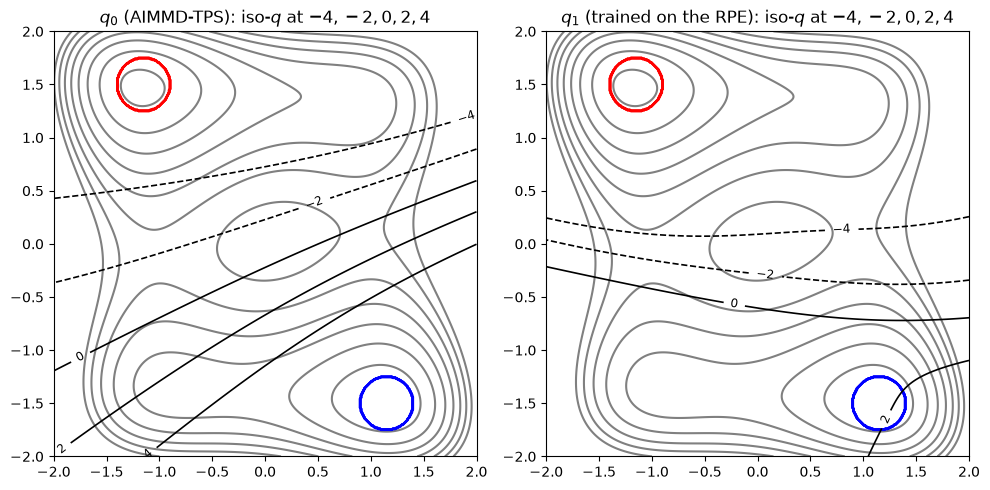

In [14]:
training_config = dict(aimmd_set.config.get("training", {}))
epochs = sizes["train_epochs"] or training_config.get("epochs", 500)

if RERUN or not retrained_model_file.exists():
    store = aimmd.Storage(str(retrained_model_file), "w")
    model_1 = aimmd_set.setup_RCModel(store)
    for module in model_1.nnet.modules():
        if isinstance(module, torch.nn.Dropout):
            module.p = 0.0
    train_data, test_data = aimmdTIS.create_train_test_split(
        desc_total, shots_total, weights=w_total, split=[4, 1], seed=42)
    n_states = len(states)
    store.save_trainset(aimmd.TrainSet(n_states=n_states, descriptors=desc_total,
                                       shot_results=shots_total, weights=w_total))
    trainset = aimmd.TrainSet(n_states=n_states, descriptors=train_data[0], shot_results=train_data[1], weights=train_data[2])
    testset = aimmd.TrainSet(n_states=n_states, descriptors=test_data[0], shot_results=test_data[1], weights=test_data[2])
    base_lr = training_config.get("base_lr", 1e-3)
    aimmdTIS.train_one_stage(
        store, model_1, trainset, testset,
        stage_name="rpe_it1",
        epochs=epochs,
        batch_size=training_config.get("batch_size", 4096),
        base_lr=base_lr,
        optimizer_cfg={"type": "adamw", "lr": base_lr, "betas": [0.9, 0.95], "eps": 1e-8, "weight_decay": 1e-4},
        plateau_patience=training_config.get("plateau_patience", 30),
        plateau_factor=training_config.get("plateau_factor", 0.5),
        min_lr=training_config.get("min_lr", 1e-7),
        warmup_epochs=training_config.get("warmup_epochs", 0),
        early_stop_patience=min(training_config.get("early_stop_patience", 30), 30),
    )
    store.close()

model_1 = load_model(retrained_model_file)
interfaces_it2 = place_interfaces(model_1)
print("next iteration, forward :", interfaces_it2["forward"])
print("next iteration, backward:", interfaces_it2["backward"])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, model, title in zip(axes, (tps_model, model_1), (r"$q_0$ (AIMMD-TPS)", r"$q_1$ (trained on the RPE)")):
    viz.plot_potential_contour(ax=ax)
    viz.plot_states(ax=ax)
    viz.plot_q_contours(model, ax=ax, levels=[-4, -2, 0, 2, 4], colors="k", linewidths=1.2)
    ax.set_title(title + r": iso-$q$ at $-4,-2,0,2,4$")
plt.tight_layout()
plt.show()

**What to look for.**
- Compared with $q_0$, the iso-$q$ lines of $q_1$ should follow the curved channel more closely and have a more
  even spacing between the states, because $q_1$ was trained on data from the whole transition region.
- The next iteration's interfaces are usually spread more evenly.
- In QUICK mode (about 70 paths per interface, 40 training epochs) the RPE and $ are noisy, and $ can look worse
  than $ in places. The notebook then only shows the mechanics; use `QUICK = False` to compare the models.

## Next steps
- **More iterations:** `examples/wolfe_quapp_iterative/run_iterative.py` repeats steps 4–7. It reuses all paths of
  earlier iterations through multi-set MBAR, and compares $q_k$ with the exact committor of this potential. Run
  `python run_iterative.py --quick` for a short test; see its README.
- **Your own system:** replace `ToyTPSSetup` with an ops-setup system (e.g. OpenMM) and `descriptors_of` /
  `descriptor_transform` with your descriptors. Steps 2–7 stay the same.